In [1]:
# Install pinned dependencies (see requirements.txt). In Colab, upload/clone the repo first or the fallback list is used.
import os, sys, subprocess
if os.path.exists("requirements.txt"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=False)
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm==1.0.30", "lime", "shap", "scikit-image",
                    "opencv-python-headless", "seaborn", "tqdm", "scipy", "openpyxl"], check=False)


In [4]:
import os, glob, random, time, json, hashlib, copy, warnings, zipfile, shutil, subprocess, sys
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, cv2
import matplotlib
if not os.environ.get("DISPLAY") and "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
try:
    from IPython.display import display
except Exception:
    display = print
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm
from skimage.restoration import denoise_tv_chambolle
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, roc_curve, auc, roc_auc_score, f1_score)
from sklearn.preprocessing import label_binarize

def _env(name, default, cast=str):
    v = os.environ.get(name)
    return default if v is None else cast(v)

# ------------------------- experiment selection (override with environment variables for batch runs) -------------------------
DATASET     = _env("DATASET", "BUS")           # BUS | MiniDDSM | CBIS_DDSM
VARIANT     = _env("VARIANT", "full")          # full | no_tvgcf | no_oga | no_residual | no_ooa   (ablation study)
SEED        = _env("SEED", 42, int)            # training seed (weight init, augmentation, OOA search)
SPLIT_SEED  = _env("SPLIT_SEED", 42, int)      # seed used only when a split file does not exist yet (splits/<DATASET>_split.csv)

# Class folders of each dataset. Folder names must match (lower-case). `normal` is the class that has no lesion mask (None if absent).
DATASETS = {
    "BUS":       dict(classes=["benign", "malignant", "normal"],                            normal="normal"),
    "MiniDDSM":  dict(classes=["benign", "malignant", "normal"],                            normal="normal"),
    "CBIS_DDSM": dict(classes=["benign", "benign_without_callback", "malignant"],           normal=None),
}
assert DATASET in DATASETS, f"DATASET must be one of {list(DATASETS)}"
CLASSES     = DATASETS[DATASET]["classes"]
NORMAL_CLS  = DATASETS[DATASET]["normal"]
NC          = len(CLASSES)
CLASS2IDX   = {c: i for i, c in enumerate(CLASSES)}

# ------------------------- ablation switches -------------------------
VARIANTS = {"full": {}, "no_tvgcf": dict(USE_TVGCF=False), "no_oga": dict(USE_OGA=False),
            "no_residual": dict(USE_RES=False), "no_ooa": dict(RUN_OOA=False)}
assert VARIANT in VARIANTS, f"VARIANT must be one of {list(VARIANTS)}"
_flags = dict(USE_TVGCF=True, USE_OGA=True, USE_RES=True, RUN_OOA=True); _flags.update(VARIANTS[VARIANT])
USE_TVGCF, USE_OGA, USE_RES, RUN_OOA = _flags["USE_TVGCF"], _flags["USE_OGA"], _flags["USE_RES"], _flags["RUN_OOA"]

# ------------------------- hyper-parameters / settings -------------------------
IMG_SIZE    = _env("IMG_SIZE", 256, int)         # multiple of 32. Swin window = IMG_SIZE//32 (224->7, 256->8, 320->10). Use 224 to get the original setting
assert IMG_SIZE % 32 == 0, "IMG_SIZE must be a multiple of 32"
BATCH       = _env("BATCH", 16, int)
SEG_EPOCHS  = _env("SEG_EPOCHS", 200, int)
CLS_EPOCHS  = _env("CLS_EPOCHS", 200, int)
PATIENCE    = _env("PATIENCE", 12, int)   # classifier early-stopping patience (was 7)
# ---- settings added by the improved pipeline ------------------------------------------------------------------------------
SEG_PATIENCE     = _env("SEG_PATIENCE", 15, int)
SEG_LR_ENC       = _env("SEG_LR_ENC", 5e-5, float)    # pretrained Swin encoder
SEG_LR_DEC       = _env("SEG_LR_DEC", 5e-4, float)    # randomly initialised decoder / heads
SEG_WARMUP       = 3                                   # linear warm-up epochs
OOF_FOLDS        = _env("OOF_FOLDS", 5, int)           # >=2: classifier is trained on OUT-OF-FOLD OAST masks (0 = old behaviour)
OOF_SEG_EPOCHS   = _env("OOF_SEG_EPOCHS", 40, int)
SEG_ENSEMBLE     = _env("SEG_ENSEMBLE", "1") == "1"    # val/test masks = mean of the main OAST and the OOF fold models
CLS_INPUT        = _env("CLS_INPUT", "channel")        # "channel": (gray, gray, OAST probability) | "emphasise": legacy dimming of the background
CLS_WEIGHT_POWER = _env("CLS_WEIGHT_POWER", 0.5, float)  # class weight = inverse-frequency ** power (1 = old, 0 = none)
MIXUP_P, MIXUP_ALPHA = _env("MIXUP_P", 0.5, float), 0.3
ENS_N            = _env("ENS_N", 3, int)               # number of classifier seeds averaged at test time
CLS_LR_WARMUP    = 2
assert CLS_INPUT in ("channel", "emphasise")
# ----------------------------------------------------------------------------------------------------------------------------
BG_FLOOR    = 0.5      # background intensity kept when the OAST lesion map is used to emphasise the lesion
PRETRAINED  = _env("PRETRAINED", "1") == "1"   # ImageNet-pretrained Swin-T / DenseNet-201 (timm). Report this in the Methods.
OOA_POP, OOA_ITERS, OOA_PROXY_EPOCHS = _env("OOA_POP", 5, int), _env("OOA_ITERS", 3, int), _env("OOA_PROXY_EPOCHS", 6, int)
RUN_CV      = _env("RUN_CV", "0") == "1"        # 10-fold CV is slow; switch on when needed
CV_EPOCHS   = _env("CV_EPOCHS", 8, int)
CV_SEG_EPOCHS = _env("CV_SEG_EPOCHS", 15, int)
CV_RETRAIN_OAST = _env("CV_RETRAIN_OAST", "1") == "1"   # True: OAST is re-trained inside every fold (no leakage). False: legacy (optimistic).
RUN_XAI     = _env("RUN_XAI", "1" if VARIANT == "full" else "0") == "1"   # Grad-CAM / LIME / SHAP (skipped for ablation runs by default)
NUM_WORKERS = _env("NUM_WORKERS", 2, int)

# ------------------------- paths -------------------------
try:                                            # Google Colab is optional
    from google.colab import drive
    drive.mount("/content/drive"); IN_COLAB = True
except Exception:
    IN_COLAB = False
DATA_ROOT = _env("DATA_ROOT", "/content/drive/MyDrive/priya dharshini/breast_datasets" if IN_COLAB else "./data")   # <DATA_ROOT>/<DATASET>/<class>/*.png
OUT_ROOT  = _env("OUT_ROOT",  "/content/drive/MyDrive/priya dharshini/breast_results"  if IN_COLAB else "./results")
SPLIT_DIR = _env("SPLIT_DIR", "./splits")       # committed to the repository so that the exact split can be reused
OUT_DIR   = f"{OUT_ROOT}/{DATASET}/{VARIANT}/seed{SEED}"
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(SPLIT_DIR, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
AMP = DEVICE == "cuda"

def set_seed(s=None):
    s = SEED if s is None else s
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
results = {}
results["config"] = dict(dataset=DATASET, variant=VARIANT, seed=SEED, split_seed=SPLIT_SEED, img_size=IMG_SIZE, pretrained=PRETRAINED,
                         use_tvgcf=USE_TVGCF, use_oga=USE_OGA, use_residual=USE_RES, run_ooa=RUN_OOA,
                         seg_epochs=SEG_EPOCHS, cls_epochs=CLS_EPOCHS, ooa=dict(pop=OOA_POP, iters=OOA_ITERS, proxy_epochs=OOA_PROXY_EPOCHS))

def save_results():
    """Write all collected numbers to <OUT_DIR>/results.json (called after every stage)."""
    with open(f"{OUT_DIR}/results.json", "w") as fh:
        json.dump(results, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

# record the exact package versions used for this run
try:
    with open(f"{OUT_DIR}/environment.txt", "w") as fh:
        fh.write(subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout)
except Exception as e:
    print("could not write environment.txt:", e)

print(f"Dataset: {DATASET} | variant: {VARIANT} | seed: {SEED} | classes: {CLASSES}")
print("Device:", DEVICE, "| torch", torch.__version__, "| timm", timm.__version__, "| pretrained:", PRETRAINED)
if DEVICE == "cpu":
    print("WARNING: no GPU detected – training will be very slow.")

results["config_improved"] = dict(seg_patience=SEG_PATIENCE, seg_lr_enc=SEG_LR_ENC, seg_lr_dec=SEG_LR_DEC, oof_folds=OOF_FOLDS, oof_seg_epochs=OOF_SEG_EPOCHS,
                                  seg_ensemble=SEG_ENSEMBLE, cls_input=CLS_INPUT, cls_weight_power=CLS_WEIGHT_POWER, mixup_p=MIXUP_P,
                                  ens_n=ENS_N, cls_patience=PATIENCE)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset: BUS | variant: full | seed: 42 | classes: ['benign', 'malignant', 'normal']
Device: cuda | torch 2.11.0+cu130 | timm 1.0.30 | pretrained: True


## 1. Load the selected dataset and split (before preprocessing)



In [5]:
DATASET_DIR = os.path.join(DATA_ROOT, DATASET)
assert os.path.isdir(DATASET_DIR), f"Dataset folder not found: {DATASET_DIR}  -> set DATA_ROOT (see README.md)"
print("Found:", sorted(os.listdir(DATASET_DIR)))


Found: ['benign', 'full', 'malignant', 'normal']


In [6]:
# In Colab, copy the dataset from Drive to the local disk once (reading thousands of files from Drive is very slow)
if IN_COLAB:
    LOCAL_ROOT = f"/content/{DATASET}_local"
    for c in CLASSES:
        src_dir = os.path.join(DATASET_DIR, c)
        assert os.path.isdir(src_dir), f"Folder not found: {src_dir}  -> check DATA_ROOT and the class sub-folder names"
        if not os.path.exists(os.path.join(LOCAL_ROOT, c)):
            shutil.copytree(src_dir, os.path.join(LOCAL_ROOT, c))
    root = LOCAL_ROOT
else:
    for c in CLASSES:
        assert os.path.isdir(os.path.join(DATASET_DIR, c)), f"Folder not found: {os.path.join(DATASET_DIR, c)}"
    root = DATASET_DIR
for c in CLASSES:
    print(f"{c:24s}: {len(os.listdir(os.path.join(root, c)))} files")

imgs, masks = {}, {}
for p in glob.glob(os.path.join(root, "**", "*.*"), recursive=True):
    if not p.lower().endswith((".png", ".jpg", ".jpeg")):
        continue
    cls = os.path.basename(os.path.dirname(p)).lower()
    if cls not in CLASS2IDX:
        continue
    name = os.path.splitext(os.path.basename(p))[0]
    if "_mask" in name:
        masks.setdefault((cls, name.split("_mask")[0]), []).append(p)   # some images have >1 mask
    else:
        imgs[(cls, name)] = p

rows = []
for (cls, name), p in imgs.items():
    rows.append(dict(image_path=p, rel_path=os.path.relpath(p, root).replace(os.sep, "/"),
                     mask_paths=sorted(masks.get((cls, name), [])), cls=cls, label=CLASS2IDX[cls]))
df = pd.DataFrame(rows).sort_values("rel_path").reset_index(drop=True)
print(f"Total images: {len(df)}")
print(df.cls.value_counts().to_string())
n_nomask = int((df.mask_paths.str.len() == 0).sum())
print("Images without any mask file:", n_nomask, "(expected only for the 'normal' class, if the dataset has one)")
if NORMAL_CLS is None:
    assert n_nomask == 0, "every image of this dataset needs a mask for segmentation"


benign                  : 891 files
malignant               : 421 files
normal                  : 266 files
Total images: 780
cls
benign       437
malignant    210
normal       133
Images without any mask file: 0 (expected only for the 'normal' class, if the dataset has one)


In [28]:
# Near-duplicate diagnostic (cheap 16x16 hash) – done BEFORE splitting, only reported, nothing is removed
def img_hash(p):
    g = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (16, 16), interpolation=cv2.INTER_AREA)
    return hashlib.md5(g.tobytes()).hexdigest()
df["hash"] = [img_hash(p) for p in tqdm(df.image_path, desc="hashing")]

# Stratified image-level split 70 / 10 / 20 (train / validation / test). The split is written to
# splits/<DATASET>_split_70_10_20.csv and re-used on the next run, so every seed / ablation variant
# is evaluated on exactly the same train / validation / test images.
SPLIT_FRACS = (0.70, 0.10, 0.20)
SPLIT_FILE = os.path.join(SPLIT_DIR, f"{DATASET}_split_70_10_20.csv")
if os.path.exists(SPLIT_FILE):
    sp = pd.read_csv(SPLIT_FILE)[["rel_path", "split"]]
    assert set(sp.rel_path) == set(df.rel_path), f"{SPLIT_FILE} does not match the files found in {root}"
    df = df.drop(columns=[c for c in ["split"] if c in df]).merge(sp, on="rel_path", how="left")
    print("Re-using saved split:", SPLIT_FILE)
else:
    train_idx, tmp_idx = train_test_split(df.index, test_size=1 - SPLIT_FRACS[0],
                                          stratify=df.label, random_state=SPLIT_SEED)
    val_idx, test_idx  = train_test_split(tmp_idx, test_size=SPLIT_FRACS[2] / (SPLIT_FRACS[1] + SPLIT_FRACS[2]),
                                          stratify=df.label[tmp_idx], random_state=SPLIT_SEED)
    df["split"] = "train"
    df.loc[val_idx, "split"] = "val"
    df.loc[test_idx, "split"] = "test"
    df[["rel_path", "cls", "label", "split", "hash"]].to_csv(SPLIT_FILE, index=False)
    print("Created and saved split:", SPLIT_FILE)
train_df, val_df, test_df = [df[df.split == s] for s in ("train", "val", "test")]

tab = pd.crosstab(df.cls, df.split)[["train", "val", "test"]]
tab["total"] = tab.sum(1)
tab.loc["Total"] = tab.sum()
tab.columns = ["Training", "Validation", "Testing", "Total"]
print("\nClass distribution (generated from the actual split – use these numbers in the manuscript tables):")
display(tab[["Total", "Training", "Validation", "Testing"]])
tab.to_csv(f"{OUT_DIR}/table_class_distribution.csv")

n_cross = int((df.groupby("hash").split.nunique() > 1).sum())
print(f"Near-duplicate groups spanning more than one split: {n_cross}  "
      f"(possible image-level leakage – patient IDs are not available in this dataset)")
results["split_counts"] = tab.to_dict()
results["near_duplicate_groups_across_splits"] = n_cross
results["split_fractions"] = dict(train=SPLIT_FRACS[0], val=SPLIT_FRACS[1], test=SPLIT_FRACS[2])
save_results()

hashing:   0%|          | 0/780 [00:00<?, ?it/s]

Created and saved split: ./splits/BUS_split_70_10_20.csv

Class distribution (generated from the actual split – use these numbers in the manuscript tables):


,Total,Training,Validation,Testing
cls,,,,
benign,437,305,44,88
malignant,210,147,21,42
normal,133,93,13,27
Total,780,545,78,157


Near-duplicate groups spanning more than one split: 1  (possible image-level leakage – patient IDs are not available in this dataset)


## 2. TVGCF preprocessing

preprocess train:   0%|          | 0/546 [00:00<?, ?it/s]

preprocess val:   0%|          | 0/117 [00:00<?, ?it/s]

preprocess test:   0%|          | 0/117 [00:00<?, ?it/s]

(546, 256, 256, 3) (117, 256, 256, 3) (117, 256, 256, 3)


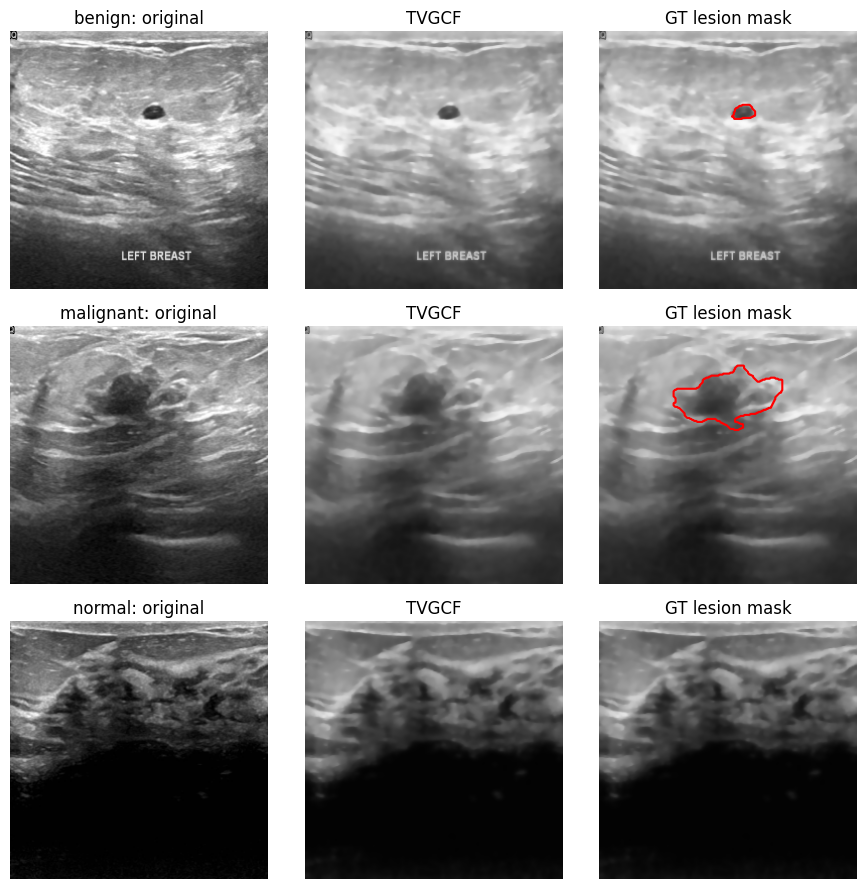

In [8]:
def tvgcf(gray_u8, tv_weight=0.1, gamma=0.8):
    g = gray_u8.astype(np.float32) / 255.0
    den = denoise_tv_chambolle(g, weight=tv_weight)
    out = np.power(np.clip(den, 0, 1), gamma)
    return (out * 255).astype(np.uint8)

def load_sample(img_path, mask_paths, apply_tvgcf=None):
    apply_tvgcf = USE_TVGCF if apply_tvgcf is None else apply_tvgcf
    g = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    g = cv2.resize(g, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    if apply_tvgcf:
        g = tvgcf(g)
    rgb = np.stack([g] * 3, -1)
    m = np.zeros((IMG_SIZE, IMG_SIZE), np.uint8)
    for mp in mask_paths:                              # union of all lesion masks of the image
        mm = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
        mm = cv2.resize(mm, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
        m = np.maximum(m, (mm > 127).astype(np.uint8))
    return rgb, m

def build_subset(sub_df, name):
    X, M = [], []
    for r in tqdm(sub_df.itertuples(), total=len(sub_df), desc=f"preprocess {name}"):
        x, m = load_sample(r.image_path, r.mask_paths)
        X.append(x); M.append(m)
    return np.stack(X), np.stack(M), sub_df.label.values.astype(np.int64)

Xtr, Mtr, ytr = build_subset(train_df, "train")
Xva, Mva, yva = build_subset(val_df, "val")
Xte, Mte, yte = build_subset(test_df, "test")
print(Xtr.shape, Xva.shape, Xte.shape)

# --- Figure: raw vs TVGCF vs ground-truth mask
fig, ax = plt.subplots(NC, 3, figsize=(9, 3 * NC), squeeze=False)
for r, c in enumerate(CLASSES):
    row = train_df[train_df.cls == c].iloc[0]
    raw, _ = load_sample(row.image_path, row.mask_paths, apply_tvgcf=False)
    enh, m = load_sample(row.image_path, row.mask_paths, apply_tvgcf=True)
    ax[r, 0].imshow(raw); ax[r, 0].set_title(f"{c}: original")
    ax[r, 1].imshow(enh); ax[r, 1].set_title("TVGCF")
    ax[r, 2].imshow(enh); ax[r, 2].contour(m, [0.5], colors="r", linewidths=1.5); ax[r, 2].set_title("GT lesion mask")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_preprocessing.png", dpi=200); plt.show()

## 3. Datasets and augmentation (augmentation is applied to the **training** subset only)

In [9]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD  = np.array([0.229, 0.224, 0.225], np.float32)

def _elastic(img, mask, alpha=120.0, sigma=8.0):
    """Smooth random deformation (about 2-3 px at 256x256), applied identically to image and mask."""
    h, w = img.shape[:2]
    dx = cv2.GaussianBlur(np.random.uniform(-1, 1, (h, w)).astype(np.float32), (0, 0), sigma) * alpha
    dy = cv2.GaussianBlur(np.random.uniform(-1, 1, (h, w)).astype(np.float32), (0, 0), sigma) * alpha
    xx, yy = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
    mx, my = xx + dx, yy + dy
    img = cv2.remap(np.ascontiguousarray(img), mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    if mask is not None:
        mask = cv2.remap(np.ascontiguousarray(mask), mx, my, cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
    return img, mask

def augment(img, mask=None, photo_ch=None):
    """Geometric transforms act on every channel; intensity/noise transforms only on the first `photo_ch` channels
    (the classifier's 3rd channel is the OAST probability and must not be brightness-shifted)."""
    h, w = img.shape[:2]
    if random.random() < 0.5:
        img = img[:, ::-1]
        mask = mask[:, ::-1] if mask is not None else None
    ang, sc = random.uniform(-20, 20), random.uniform(0.8, 1.2)
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, sc)
    M[:, 2] += [random.uniform(-0.08, 0.08) * w, random.uniform(-0.08, 0.08) * h]
    img = cv2.warpAffine(np.ascontiguousarray(img), M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
    if mask is not None:
        mask = cv2.warpAffine(np.ascontiguousarray(mask), M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
    if random.random() < 0.3:
        img, mask = _elastic(img, mask)
    k = img.shape[2] if photo_ch is None else photo_ch
    a, b = random.uniform(0.8, 1.2), random.uniform(-20, 20)
    f = img.astype(np.float32)
    f[..., :k] = f[..., :k] * a + b
    if random.random() < 0.3:                                                   # speckle-like noise
        f[..., :k] += np.random.normal(0, random.uniform(2, 8), (h, w, 1)).astype(np.float32)
    return np.clip(f, 0, 255).astype(np.uint8), mask

def to_tensor(img_u8):
    x = (img_u8.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1)))

class SegDS(Dataset):
    def __init__(self, X, M, train): self.X, self.M, self.train = X, M, train
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        img, m = self.X[i], self.M[i]
        if self.train: img, m = augment(img, m)
        return to_tensor(img), torch.from_numpy(np.ascontiguousarray(m[None]).astype(np.float32))

class ClsDS(Dataset):
    def __init__(self, X, y, train): self.X, self.y, self.train = X, y, train
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        img = self.X[i]
        if self.train: img, _ = augment(img, None, photo_ch=2 if CLS_INPUT == "channel" else None)
        return to_tensor(img), int(self.y[i])


## 4. OAST – Orientation-guided Attention Swin Transformer (segmentation)
* Encoder: Swin-T (ImageNet pre-trained, 4 stages, window = IMG_SIZE/32)
* Orientation prior: fixed bank of oriented Gabor filters → orientation-energy maps
* Orientation-guided attention (OGA): the prior is pooled to each stage resolution and converted to a gate that re-weights the stage features
* Decoder: U-Net style with skip connections **plus a full-resolution convolutional stem skip** (the stride-4 Swin output alone gives coarse boundaries) and deep supervision on the two deepest decoder stages
* Loss: BCE + Dice + Focal-Tversky (α=0.7 favours recall of small lesions)
* Optimisation: separate learning rates for encoder / decoder, linear warm-up + cosine decay
* Inference: horizontal-flip TTA; threshold and connected-component post-processing are tuned on the **validation** set


In [10]:
class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.b = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True))
    def forward(self, x): return self.b(x)

class OrientationPrior(nn.Module):
    def __init__(self, n_orient=4, ksize=15):
        super().__init__()
        ks = [cv2.getGaborKernel((ksize, ksize), 4.0, np.pi * k / n_orient, 8.0, 0.5, 0) for k in range(n_orient)]
        self.register_buffer("w", torch.tensor(np.stack(ks)[:, None], dtype=torch.float32))
    def forward(self, x):
        g = x.mean(1, keepdim=True)
        return torch.abs(F.conv2d(g, self.w, padding=self.w.shape[-1] // 2))

class OrientationGuidedAttention(nn.Module):
    def __init__(self, ch, n_orient=4):
        super().__init__()
        self.gate = nn.Sequential(nn.Conv2d(n_orient, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(True),
                                  nn.Conv2d(32, ch, 1), nn.Sigmoid())
    def forward(self, feat, prior):
        prior = F.adaptive_avg_pool2d(prior, feat.shape[-2:])
        return feat * (1 + self.gate(prior))

class OAST(nn.Module):
    def __init__(self, pretrained=True, use_oga=True):
        super().__init__()
        self.use_oga = use_oga
        self.encoder = timm.create_model("swin_tiny_patch4_window7_224", pretrained=pretrained, features_only=True,
                                         img_size=IMG_SIZE, window_size=IMG_SIZE // 32)
        self.chs = self.encoder.feature_info.channels()            # [96, 192, 384, 768]
        self.prior = OrientationPrior(4)
        self.oga = nn.ModuleList([OrientationGuidedAttention(c) for c in self.chs])
        self.dec3 = ConvBlock(self.chs[3] + self.chs[2], 256)
        self.dec2 = ConvBlock(256 + self.chs[1], 128)
        self.dec1 = ConvBlock(128 + self.chs[0], 64)
        self.stem = ConvBlock(3, 32)                               # full-resolution detail branch (new)
        self.dec0 = ConvBlock(64 + 32, 32)                         # fuses stride-4 decoder output with full-res detail (new)
        self.out  = nn.Conv2d(32, 1, 1)
        self.aux3 = nn.Conv2d(256, 1, 1); self.aux2 = nn.Conv2d(128, 1, 1)   # deep-supervision heads (training only)
    @staticmethod
    def _up(x, ref): return F.interpolate(x, size=ref.shape[-2:], mode="bilinear", align_corners=False)
    def forward(self, x, aux=False):
        prior = self.prior(x)
        prior = prior / (prior.amax(dim=(1, 2, 3), keepdim=True) + 1e-6)
        feats = []
        for f, ch, att in zip(self.encoder(x), self.chs, self.oga):
            if f.shape[1] != ch and f.shape[-1] == ch:              # timm Swin returns NHWC
                f = f.permute(0, 3, 1, 2).contiguous()
            feats.append(att(f, prior) if self.use_oga else f)
        f0, f1, f2, f3 = feats
        d3 = self.dec3(torch.cat([self._up(f3, f2), f2], 1))
        d2 = self.dec2(torch.cat([self._up(d3, f1), f1], 1))
        d1 = self.dec1(torch.cat([self._up(d2, f0), f0], 1))
        d0 = self.dec0(torch.cat([self._up(d1, x), self.stem(x)], 1))
        out = self.out(d0)                                          # logits at input resolution
        if aux:
            return out, [self._up(self.aux3(d3), x), self._up(self.aux2(d2), x)]
        return out

def dice_loss(logits, target, eps=1e-6):
    p = torch.sigmoid(logits)
    inter = (p * target).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + target.sum((1, 2, 3))
    return 1 - ((2 * inter + eps) / (den + eps)).mean()

def focal_tversky_loss(logits, target, alpha=0.7, beta=0.3, gamma=0.75, smooth=1.0):
    """alpha > beta penalises missed lesion pixels (FN) more than false alarms (FP); gamma < 1 focuses on hard images.
    Images without a lesion (normal class) are penalised for any predicted foreground."""
    p = torch.sigmoid(logits)
    tp = (p * target).sum((1, 2, 3)); fn = ((1 - p) * target).sum((1, 2, 3)); fp = (p * (1 - target)).sum((1, 2, 3))
    ti = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    return ((1 - ti).clamp(min=1e-6) ** gamma).mean()

def seg_loss(logits, target, bce):
    return bce(logits, target) + dice_loss(logits, target) + focal_tversky_loss(logits, target)

@torch.no_grad()
def batch_dice(logits, target, eps=1e-6):
    p = (torch.sigmoid(logits) > 0.5).float()
    inter = (p * target).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + target.sum((1, 2, 3))
    return (2 * inter + eps) / (den + eps)

def make_sched(opt, epochs, warm=2, floor=0.01):
    """Linear warm-up for `warm` epochs, then cosine decay to `floor` x base LR (works with several parameter groups)."""
    import math
    def f(ep):
        if ep < warm: return (ep + 1) / warm
        t = (ep - warm) / max(1, epochs - warm)
        return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * min(1.0, t)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def train_seg(model, tr_loader, va_loader, epochs=SEG_EPOCHS, lr_enc=None, lr_dec=None, patience=None, verbose=True):
    lr_enc = SEG_LR_ENC if lr_enc is None else lr_enc
    lr_dec = SEG_LR_DEC if lr_dec is None else lr_dec
    patience = SEG_PATIENCE if patience is None else patience
    model.to(DEVICE)
    enc = [p for n, p in model.named_parameters() if n.startswith("encoder.")]
    oth = [p for n, p in model.named_parameters() if not n.startswith("encoder.")]
    opt = torch.optim.AdamW([{"params": enc, "lr": lr_enc}, {"params": oth, "lr": lr_dec}], weight_decay=1e-4)
    sched = make_sched(opt, epochs, warm=min(SEG_WARMUP, max(1, epochs // 4)))
    scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
    bce = nn.BCEWithLogitsLoss()
    hist = dict(train_loss=[], val_loss=[], val_dice=[])
    best, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train(); tl = n = 0
        for xb, mb in tr_loader:
            xb, mb = xb.to(DEVICE), mb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, enabled=AMP):
                lg, aux = model(xb, aux=True)
            lg = lg.float()
            loss = seg_loss(lg, mb, bce) + 0.3 * sum(bce(a.float(), mb) + dice_loss(a.float(), mb) for a in aux)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(xb); n += len(xb)
        sched.step()
        model.eval(); vl = vn = 0; vd = []
        with torch.no_grad():
            for xb, mb in va_loader:
                xb, mb = xb.to(DEVICE), mb.to(DEVICE)
                with torch.autocast(device_type=DEVICE, enabled=AMP):
                    lg = model(xb)
                lg = lg.float()
                vl += seg_loss(lg, mb, bce).item() * len(xb); vn += len(xb)
                vd.append(batch_dice(lg, mb).cpu())
        vd = torch.cat(vd).mean().item()
        hist["train_loss"].append(tl / n); hist["val_loss"].append(vl / vn); hist["val_dice"].append(vd)
        if verbose: print(f"[OAST] ep {ep+1:02d}/{epochs} train_loss {tl/n:.4f} val_loss {vl/vn:.4f} val_dice {vd:.4f}")
        if vd > best:
            best, bad = vd, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                if verbose: print("Early stopping.")
                break
    model.load_state_dict(best_state)
    return hist, model

@torch.no_grad()
def predict_seg(model, X, bs=32, tta=True):
    """Lesion probability maps (N,H,W). tta=True averages the prediction with that of the horizontally flipped image."""
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = torch.stack([to_tensor(im) for im in X[i:i + bs]]).to(DEVICE)
        with torch.autocast(device_type=DEVICE, enabled=AMP):
            p = torch.sigmoid(model(xb).float())
            if tta:
                p = 0.5 * (p + torch.sigmoid(model(xb.flip(-1)).float()).flip(-1))
        out.append(p.squeeze(1).cpu().numpy())
    return np.concatenate(out)

set_seed()
seg_tr = DataLoader(SegDS(Xtr, Mtr, True), batch_size=BATCH, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, pin_memory=True)
seg_va = DataLoader(SegDS(Xva, Mva, False), batch_size=BATCH * 2, shuffle=False, num_workers=NUM_WORKERS)
oast = OAST(pretrained=PRETRAINED, use_oga=USE_OGA)
seg_hist, oast = train_seg(oast, seg_tr, seg_va)
torch.save(oast.state_dict(), f"{OUT_DIR}/oast_best.pt")


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[OAST] ep 01/80 train_loss 2.9395 val_loss 2.2168 val_dice 0.3334
[OAST] ep 02/80 train_loss 2.5932 val_loss 1.8178 val_dice 0.5334
[OAST] ep 03/80 train_loss 2.3941 val_loss 1.7234 val_dice 0.6244
[OAST] ep 04/80 train_loss 2.2046 val_loss 1.6464 val_dice 0.5721
[OAST] ep 05/80 train_loss 2.0621 val_loss 1.5390 val_dice 0.5993
[OAST] ep 06/80 train_loss 1.9470 val_loss 1.3636 val_dice 0.6124
[OAST] ep 07/80 train_loss 1.8257 val_loss 1.4147 val_dice 0.6201
[OAST] ep 08/80 train_loss 1.7151 val_loss 1.3617 val_dice 0.6249
[OAST] ep 09/80 train_loss 1.6158 val_loss 1.1898 val_dice 0.6374
[OAST] ep 10/80 train_loss 1.5067 val_loss 1.1458 val_dice 0.6285
[OAST] ep 11/80 train_loss 1.4626 val_loss 1.0605 val_dice 0.7055
[OAST] ep 12/80 train_loss 1.3867 val_loss 1.0187 val_dice 0.6977
[OAST] ep 13/80 train_loss 1.2970 val_loss 1.0818 val_dice 0.6952
[OAST] ep 14/80 train_loss 1.2977 val_loss 1.0632 val_dice 0.7046
[OAST] ep 15/80 train_loss 1.2659 val_loss 1.0406 val_dice 0.6894
[OAST] ep 

### OAST out-of-fold masks and ensemble
The classifier is trained on the OAST masks of the **training** images. If those come from a model that was trained on the same images they are almost perfect, whereas
validation/test masks are noisier (missed or spurious lesions) – the classifier then over-trusts the mask. Here each training image is segmented by a fold model that
**never saw it** (`OOF_FOLDS`), so the classifier learns from realistic masks. Validation/test masks are the mean of the main OAST and the fold models (`SEG_ENSEMBLE`).
Set `OOF_FOLDS=0` to reproduce the old behaviour.


In [11]:
Pva_list = [predict_seg(oast, Xva)]
Pte_list = [predict_seg(oast, Xte)]
if OOF_FOLDS >= 2:
    Ptr = np.zeros(Xtr.shape[:3], np.float32)
    skf_oof = StratifiedKFold(OOF_FOLDS, shuffle=True, random_state=SEED)
    for k, (a, b) in enumerate(skf_oof.split(Xtr, ytr), 1):
        set_seed(SEED + 100 + k)
        tr_k = DataLoader(SegDS(Xtr[a], Mtr[a], True), batch_size=BATCH, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, pin_memory=True)
        m_k = OAST(pretrained=PRETRAINED, use_oga=USE_OGA)
        _, m_k = train_seg(m_k, tr_k, seg_va, epochs=OOF_SEG_EPOCHS, verbose=False)      # validation set only used for early stopping
        Ptr[b] = predict_seg(m_k, Xtr[b])                                               # predicted by a model that did not see these images
        if SEG_ENSEMBLE:
            Pva_list.append(predict_seg(m_k, Xva)); Pte_list.append(predict_seg(m_k, Xte))
        del m_k; torch.cuda.empty_cache()
        print(f"OOF fold {k}/{OOF_FOLDS} done")
else:
    Ptr = predict_seg(oast, Xtr)                      # legacy: masks of images the model was trained on (optimistic)
Pva, Pte = np.mean(Pva_list, 0), np.mean(Pte_list, 0)
n_members = len(Pva_list)
print(f"Validation/test masks: mean of {n_members} OAST model(s); training masks: {'out-of-fold' if OOF_FOLDS >= 2 else 'in-sample (legacy)'}")
results["oast_ensemble_members"] = n_members; results["oof_folds"] = OOF_FOLDS
save_results()


OOF fold 1/5 done
OOF fold 2/5 done
OOF fold 3/5 done
OOF fold 4/5 done
OOF fold 5/5 done
Validation/test masks: mean of 6 OAST model(s); training masks: out-of-fold


### Segmentation results on the held-out test set
IoU and the Jaccard index are the same quantity, so they are reported once as "IoU (= Jaccard)".

Selected on validation: threshold 0.40, keep-largest-component False


,thr,keep_largest,val_lesion_dice,val_normal_fp_rate,score
4,0.40,False,0.7788,0.15,0.7713
6,0.45,False,0.7783,0.15,0.7708
2,0.35,False,0.7789,0.20,0.7689
8,0.50,False,0.7763,0.15,0.7688
0,0.30,False,0.7784,0.25,0.7659
10,0.55,False,0.7730,0.15,0.7655


Lesion segmentation – test set (benign + malignant images):


dice             iou         precision          recall        
             mean     std    mean     std      mean     std    mean     std
cls                                                                        
benign     0.8756  0.1386  0.7983  0.1652    0.8735  0.1252  0.9148  0.1540
malignant  0.7616  0.2820  0.6748  0.2752    0.7779  0.3003  0.7946  0.2694

Overall (lesion images):


,mean,std
dice,0.8392,0.2017
iou,0.7588,0.2133
precision,0.8430,0.2020
recall,0.8764,0.2047


Normal images: mean predicted lesion area = 0.254% of image; 10.0% of normal images have >0.5% predicted lesion area (false-positive rate)


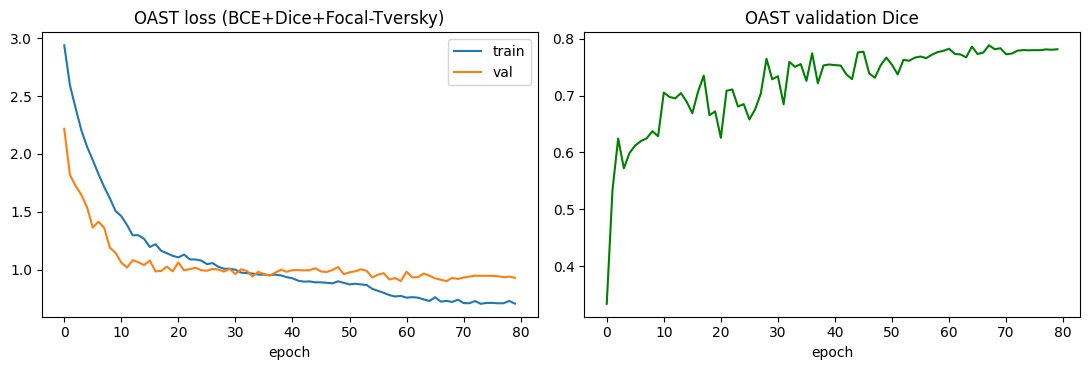

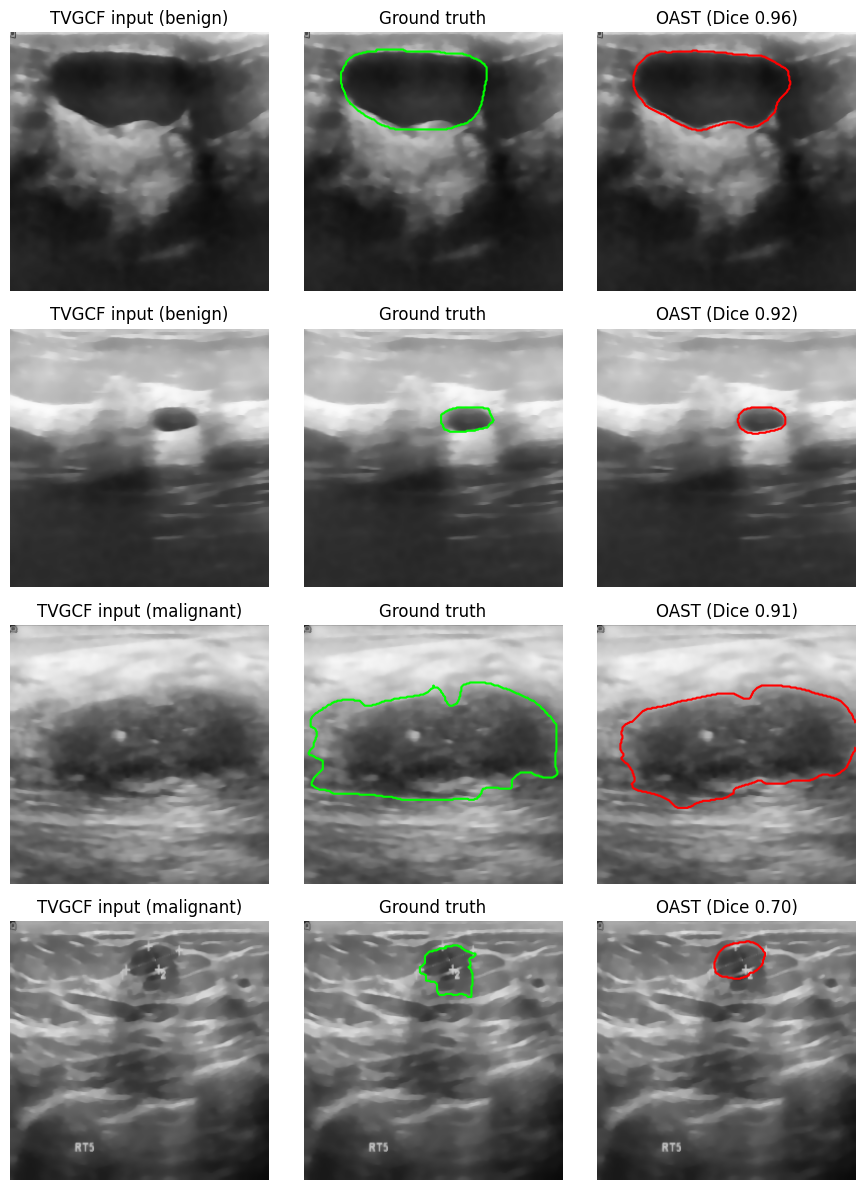

In [12]:
from scipy.ndimage import binary_fill_holes

SEG_THR, SEG_KEEP_LARGEST, SEG_MIN_FRAC = 0.5, False, 0.0005    # SEG_THR / SEG_KEEP_LARGEST are tuned on the VALIDATION set below

def binarize(P, thr=None, keep_largest=None, min_frac=None):
    """Probability maps -> binary masks: threshold, drop tiny components, optionally keep only the largest one, fill holes."""
    thr = SEG_THR if thr is None else thr
    keep_largest = SEG_KEEP_LARGEST if keep_largest is None else keep_largest
    min_frac = SEG_MIN_FRAC if min_frac is None else min_frac
    out = np.zeros(P.shape, np.uint8)
    for i in range(len(P)):
        m = (P[i] > thr).astype(np.uint8)
        if m.any():
            _, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
            areas = st[1:, cv2.CC_STAT_AREA]
            keep = np.where(areas >= min_frac * m.size)[0] + 1
            if keep_largest and len(keep):
                keep = [keep[int(np.argmax(areas[np.asarray(keep) - 1]))]]
            m = binary_fill_holes(np.isin(lab, keep)).astype(np.uint8)
        out[i] = m
    return out

def _dice_arr(pred, M):
    inter = (pred & M).sum((1, 2)).astype(np.float64); ps = pred.sum((1, 2)); gs = M.sum((1, 2))
    return (2 * inter + 1e-6) / (ps + gs + 1e-6)

# ---- tune threshold + post-processing on the validation set only (the test set is never used for any choice)
is_les_va = (yva != CLASS2IDX[NORMAL_CLS]) if NORMAL_CLS else np.ones(len(yva), bool)
grid, best_score = [], -1
for thr in np.arange(0.30, 0.601, 0.05):
    for kl in (False, True):
        pred = binarize(Pva, thr, kl)
        d = _dice_arr(pred, Mva)
        fp = float((pred[~is_les_va].mean((1, 2)) > 0.005).mean()) if (~is_les_va).any() else 0.0
        score = float(d[is_les_va].mean()) - 0.05 * fp                    # lesion Dice, lightly penalising false alarms on normal images
        grid.append(dict(thr=round(float(thr), 2), keep_largest=kl, val_lesion_dice=round(float(d[is_les_va].mean()), 4), val_normal_fp_rate=round(fp, 3), score=round(score, 4)))
        if score > best_score: best_score, SEG_THR, SEG_KEEP_LARGEST = score, float(thr), kl
print(f"Selected on validation: threshold {SEG_THR:.2f}, keep-largest-component {SEG_KEEP_LARGEST}")
display(pd.DataFrame(grid).sort_values("score", ascending=False).head(6))

PBte = binarize(Pte)

def seg_eval(P, M, labels):
    pred = binarize(P); rows = []
    for i in range(len(M)):
        inter = int((pred[i] & M[i]).sum()); union = int((pred[i] | M[i]).sum())
        ps, gs = int(pred[i].sum()), int(M[i].sum())
        rows.append(dict(cls=CLASSES[labels[i]],
                         dice=(2 * inter + 1e-6) / (ps + gs + 1e-6), iou=(inter + 1e-6) / (union + 1e-6),
                         precision=inter / ps if ps > 0 else 0.0, recall=inter / gs if gs > 0 else np.nan,
                         pred_area=ps / M[i].size, gt_area=gs / M[i].size))
    return pd.DataFrame(rows)

seg_df = seg_eval(Pte, Mte, yte)
les = seg_df[seg_df.cls != NORMAL_CLS] if NORMAL_CLS else seg_df
summ = les.groupby("cls")[["dice", "iou", "precision", "recall"]].agg(["mean", "std"]).round(4)
overall = les[["dice", "iou", "precision", "recall"]].agg(["mean", "std"]).round(4).T
print("Lesion segmentation – test set (benign + malignant images):")
display(summ)
print("Overall (lesion images):")
display(overall)
if NORMAL_CLS:
    norm = seg_df[seg_df.cls == NORMAL_CLS]
    print(f"Normal images: mean predicted lesion area = {100*norm.pred_area.mean():.3f}% of image; "
          f"{100*(norm.pred_area > 0.005).mean():.1f}% of normal images have >0.5% predicted lesion area (false-positive rate)")
summ.to_csv(f"{OUT_DIR}/table_segmentation_by_class.csv"); overall.to_csv(f"{OUT_DIR}/table_segmentation_overall.csv")
results["segmentation"] = dict(thr=float(SEG_THR), keep_largest=bool(SEG_KEEP_LARGEST), min_comp_frac=SEG_MIN_FRAC, ensemble_members=n_members,
                               dice_mean=float(les.dice.mean()), iou_mean=float(les.iou.mean()),
                               precision_mean=float(les.precision.mean()), recall_mean=float(les.recall.mean()))
save_results()

# training curves
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(seg_hist["train_loss"], label="train"); ax[0].plot(seg_hist["val_loss"], label="val"); ax[0].set_title("OAST loss (BCE+Dice+Focal-Tversky)"); ax[0].legend()
ax[1].plot(seg_hist["val_dice"], color="g"); ax[1].set_title("OAST validation Dice")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_oast_training.png", dpi=200); plt.show()

# qualitative overlays
sel = [i for k in range(min(NC, 2)) for i in list(np.where(yte == k)[0][:2])]
fig, ax = plt.subplots(len(sel), 3, figsize=(9, 3 * len(sel)))
for r, i in enumerate(sel):
    ax[r, 0].imshow(Xte[i]); ax[r, 0].set_title(f"TVGCF input ({CLASSES[yte[i]]})")
    ax[r, 1].imshow(Xte[i]); ax[r, 1].contour(Mte[i], [0.5], colors="lime", linewidths=1.5); ax[r, 1].set_title("Ground truth")
    ax[r, 2].imshow(Xte[i]); ax[r, 2].contour(PBte[i], [0.5], colors="red", linewidths=1.5)
    ax[r, 2].set_title(f"OAST (Dice {seg_df.dice[i]:.2f})")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_segmentation_examples.png", dpi=200); plt.show()

## 5. DSORCNN classifier
DenseNet-201 dense features → multi-scale spatial block (1×1, 3×3, dilated 3×3 d=2, d=3) → residual block → GAP → FC.
The input is the TVGCF image in channels 0–1 and the **OAST lesion probability in channel 2** (`CLS_INPUT="channel"`), so the classifier always sees the whole image
(a missed lesion no longer turns a benign image into a uniformly dimmed "normal-looking" one) and still only relies on predicted – never ground-truth – masks.
Training uses out-of-fold masks, Mixup, softened class weights and LR warm-up; testing uses an ensemble of `ENS_N` seeds with horizontal-flip TTA.


In [13]:
def emphasise(X, P, floor=BG_FLOOR):
    """Classifier input from the TVGCF image X (N,H,W,3 uint8) and the OAST probability P (N,H,W)."""
    if CLS_INPUT == "channel":
        out = X.copy()
        out[..., 2] = np.clip(P * 255.0, 0, 255).astype(np.uint8)       # (gray, gray, lesion probability)
        return out
    out = X.astype(np.float32) * (floor + (1 - floor) * P[..., None])  # legacy: dim the background
    return np.clip(out, 0, 255).astype(np.uint8)

Ctr, Cva, Cte = emphasise(Xtr, Ptr), emphasise(Xva, Pva), emphasise(Xte, Pte)

class MultiScaleBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        b = cout // 4
        def cbr(k, d): return nn.Sequential(nn.Conv2d(cin, b, k, padding=d * (k // 2), dilation=d, bias=False), nn.BatchNorm2d(b), nn.ReLU())
        self.b1, self.b3, self.b5, self.b7 = cbr(1, 1), cbr(3, 1), cbr(3, 2), cbr(3, 3)
        self.fuse = nn.Sequential(nn.Conv2d(4 * b, cout, 1, bias=False), nn.BatchNorm2d(cout), nn.ReLU())
    def forward(self, x):
        return self.fuse(torch.cat([self.b1(x), self.b3(x), self.b5(x), self.b7(x)], 1))

class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch), nn.ReLU(),
                               nn.Conv2d(ch, ch, 3, padding=1, bias=False), nn.BatchNorm2d(ch))
        self.act = nn.ReLU()
    def forward(self, x): return self.act(x + self.f(x))

class DSORCNN(nn.Module):
    def __init__(self, n_classes=NC, dropout=0.3, pretrained=None, use_res=None):
        super().__init__()
        pretrained = PRETRAINED if pretrained is None else pretrained
        self.use_res = USE_RES if use_res is None else use_res
        self.backbone = timm.create_model("densenet201", pretrained=pretrained)
        nf = self.backbone.num_features                              # 1920
        self.ms = MultiScaleBlock(nf, 512)
        self.res = ResBlock(512) if self.use_res else nn.Identity()
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(512, n_classes)
    def forward(self, x):
        x = self.backbone.forward_features(x)
        x = self.res(self.ms(x))
        return self.fc(self.drop(x.mean((2, 3))))

@torch.no_grad()
def evaluate_cls(model, loader, tta=False):
    model.eval(); P, Y = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        with torch.autocast(device_type=DEVICE, enabled=AMP):
            pr = F.softmax(model(xb).float(), 1)
            if tta: pr = 0.5 * (pr + F.softmax(model(xb.flip(-1)).float(), 1))
        P.append(pr.cpu().numpy()); Y.append(yb.numpy())
    P, Y = np.concatenate(P), np.concatenate(Y)
    return Y, P.argmax(1), P

def evaluate_ens(models, loader, tta=True):
    """Average the class probabilities of several models (loader must not shuffle)."""
    outs = [evaluate_cls(m, loader, tta) for m in models]
    P = np.mean([o[2] for o in outs], 0)
    return outs[0][0], P.argmax(1), P

def train_cls(model, tr_loader, va_loader, epochs, lr, wd, patience=PATIENCE, class_weights=None, verbose=True, mixup_p=None):
    mixup_p = MIXUP_P if mixup_p is None else mixup_p
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = make_sched(opt, epochs, warm=min(CLS_LR_WARMUP, max(1, epochs // 4)))
    crit = nn.CrossEntropyLoss(weight=None if class_weights is None else class_weights.to(DEVICE), label_smoothing=0.1)
    scaler = torch.amp.GradScaler(DEVICE, enabled=AMP)
    hist = dict(train_loss=[], val_loss=[], val_acc=[], val_f1=[])
    best, best_state, bad = -1, None, 0
    for ep in range(epochs):
        model.train(); tl = n = 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            use_mix = mixup_p > 0 and random.random() < mixup_p
            if use_mix:                                                     # Mixup: regularises the small training set
                lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA)); perm = torch.randperm(len(xb), device=xb.device)
                xb, yb2 = lam * xb + (1 - lam) * xb[perm], yb[perm]
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, enabled=AMP):
                lg = model(xb)
            lg = lg.float()
            loss = lam * crit(lg, yb) + (1 - lam) * crit(lg, yb2) if use_mix else crit(lg, yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(xb); n += len(xb)
        sched.step(); hist["train_loss"].append(tl / n)
        if va_loader is None:
            continue
        yt, yp, pr = evaluate_cls(model, va_loader)
        vloss = float(-np.log(pr[np.arange(len(yt)), yt] + 1e-8).mean())
        vacc, vf1 = accuracy_score(yt, yp), f1_score(yt, yp, average="macro")
        hist["val_loss"].append(vloss); hist["val_acc"].append(vacc); hist["val_f1"].append(vf1)
        if verbose:
            print(f"[DSORCNN] ep {ep+1:02d}/{epochs} train_loss {tl/n:.4f} val_loss {vloss:.4f} val_acc {vacc:.4f} val_macroF1 {vf1:.4f}")
        if vf1 > best:
            best, bad = vf1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                if verbose: print("Early stopping.")
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return hist, model

def make_cls_loaders(Xa, ya, Xb=None, yb=None, bs=BATCH):
    tr = DataLoader(ClsDS(Xa, ya, True), batch_size=bs, shuffle=True, drop_last=True, num_workers=NUM_WORKERS, pin_memory=True)
    va = None if Xb is None else DataLoader(ClsDS(Xb, yb, False), batch_size=bs * 2, shuffle=False, num_workers=NUM_WORKERS)
    return tr, va

cls_weights = torch.tensor(len(ytr) / (NC * np.bincount(ytr, minlength=NC)), dtype=torch.float32) ** CLS_WEIGHT_POWER
cls_weights = cls_weights / cls_weights.mean()
print("Class weights:", dict(zip(CLASSES, cls_weights.numpy().round(3))))

Class weights: {'benign': np.float32(0.705), 'malignant': np.float32(1.017), 'normal': np.float32(1.278)}


## 6. OOA hyper-parameter optimisation


model.safetensors: reconstructing file:   0%|          |  0.00B / 81.1MB            

model.safetensors: downloading bytes:           |  0.00B            

  eval 01: lr=3.53e-04 wd=5.70e-05 dropout=0.53 -> val macro-F1 0.8390
  eval 02: lr=2.48e-04 wd=2.38e-06 dropout=0.59 -> val macro-F1 0.8706
  eval 03: lr=3.33e-04 wd=1.39e-03 dropout=0.16 -> val macro-F1 0.8643
  eval 04: lr=7.96e-05 wd=3.04e-05 dropout=0.56 -> val macro-F1 0.8189
  eval 05: lr=1.94e-04 wd=1.95e-03 dropout=0.32 -> val macro-F1 0.8304
OOA iteration 1/3
  eval 06: lr=3.31e-04 wd=3.01e-06 dropout=0.60 -> val macro-F1 0.8262
  eval 07: lr=4.01e-04 wd=1.00e-06 dropout=0.58 -> val macro-F1 0.8401
  eval 08: lr=2.90e-04 wd=1.42e-05 dropout=0.46 -> val macro-F1 0.8328
  eval 09: lr=8.63e-05 wd=6.75e-05 dropout=0.39 -> val macro-F1 0.8402
  eval 10: lr=3.51e-04 wd=1.25e-06 dropout=0.60 -> val macro-F1 0.8497
OOA iteration 2/3
  eval 11: lr=2.18e-04 wd=1.46e-06 dropout=0.60 -> val macro-F1 0.8580
  eval 12: lr=2.87e-04 wd=1.22e-06 dropout=0.58 -> val macro-F1 0.8627
  eval 13: lr=2.31e-04 wd=8.93e-04 dropout=0.17 -> val macro-F1 0.8561
  eval 14: lr=2.90e-04 wd=2.69e-06 dropou

,eval,lr,weight_decay,dropout,val_macro_f1
0,1,0.000353,0.000057,0.529299,0.839013
1,2,0.000248,0.000002,0.587811,0.870619
2,3,0.000333,0.001394,0.164057,0.864324
3,4,0.000080,0.000030,0.563382,0.818875
4,5,0.000194,0.001955,0.321707,0.830446
5,6,0.000331,0.000003,0.596823,0.826209
6,7,0.000401,0.000001,0.581571,0.840125
7,8,0.000290,0.000014,0.459309,0.832764
8,9,0.000086,0.000067,0.392003,0.840173
9,10,0.000351,0.000001,0.600000,0.849678


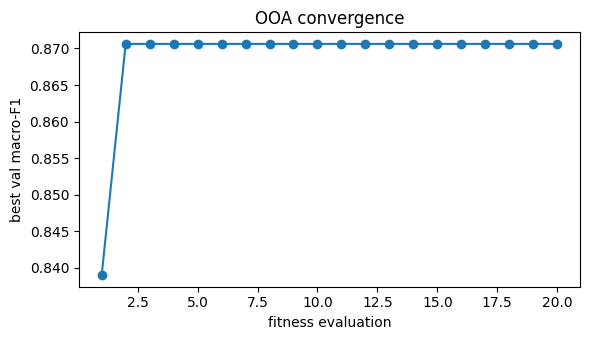

Selected hyper-parameters: {'lr': 0.0002481624443014984, 'weight_decay': 2.380725871895354e-06, 'dropout': 0.5878111758183779}
Selected hyper-parameters: {'lr': 0.0002481624443014984, 'weight_decay': 2.380725871895354e-06, 'dropout': 0.5878111758183779}


In [14]:
LO = np.array([-5.0, -6.0, 0.1]); HI = np.array([-3.0, -2.0, 0.6])
tr_loader_o, va_loader_o = make_cls_loaders(Ctr, ytr, Cva, yva)
ooa_log = []

def fitness(u):                                   # u in [0,1]^3
    theta = LO + u * (HI - LO)
    lr, wd, dr = 10 ** theta[0], 10 ** theta[1], float(theta[2])
    set_seed()
    m = DSORCNN(dropout=dr)
    hist, m = train_cls(m, tr_loader_o, va_loader_o, OOA_PROXY_EPOCHS, lr, wd, patience=99, class_weights=cls_weights, verbose=False)
    f = max(hist["val_f1"])
    ooa_log.append(dict(eval=len(ooa_log) + 1, lr=lr, weight_decay=wd, dropout=dr, val_macro_f1=f))
    print(f"  eval {len(ooa_log):02d}: lr={lr:.2e} wd={wd:.2e} dropout={dr:.2f} -> val macro-F1 {f:.4f}")
    del m; torch.cuda.empty_cache()
    return f

def ooa_optimize(fit_fn, d=3, pop=OOA_POP, iters=OOA_ITERS, seed=SEED):
    rng = np.random.default_rng(seed)
    U = rng.random((pop, d)); fit = np.array([fit_fn(u) for u in U])
    for t in range(1, iters + 1):
        print(f"OOA iteration {t}/{iters}")
        best = U[fit.argmax()].copy()
        for i in range(pop):
            if rng.random() < 0.5:                                     # exploration: forage towards a fitter peer
                better = np.where(fit > fit[i])[0]
                tgt = U[rng.choice(better)] if len(better) else best
                cand = U[i] + rng.random(d) * (tgt - U[i]) + rng.normal(0, 0.05, d)
            else:                                                      # exploitation: shrinking search around the nest
                cand = best + (1 - t / (iters + 1)) * (rng.random(d) - 0.5) * 0.5
            cand = np.clip(cand, 0, 1)
            f = fit_fn(cand)
            if f > fit[i]: U[i], fit[i] = cand, f
    return U[fit.argmax()], float(fit.max())

if RUN_OOA:
    u_best, f_best = ooa_optimize(fitness)
    th = LO + u_best * (HI - LO)
    best_hp = dict(lr=float(10 ** th[0]), weight_decay=float(10 ** th[1]), dropout=float(th[2]))
    ooa_df = pd.DataFrame(ooa_log); ooa_df.to_csv(f"{OUT_DIR}/table_ooa_search.csv", index=False)
    display(ooa_df.round(6))
    plt.figure(figsize=(6, 3.5))
    plt.plot(ooa_df["eval"], ooa_df["val_macro_f1"].cummax(), marker="o")
    plt.xlabel("fitness evaluation"); plt.ylabel("best val macro-F1"); plt.title("OOA convergence")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_ooa_convergence.png", dpi=200); plt.show()
    print("Selected hyper-parameters:", best_hp)
    results["hyperparameters"] = best_hp
else:
    best_hp = dict(lr=1e-4, weight_decay=1e-4, dropout=0.3)
print("Selected hyper-parameters:", best_hp)
results["hyperparameters"] = best_hp
results["ooa_note"] = ("simplified OOA: population %d, %d iterations, %d proxy epochs per fitness evaluation" % (OOA_POP, OOA_ITERS, OOA_PROXY_EPOCHS)) if RUN_OOA else "OOA skipped (default hyper-parameters)"
save_results()

## 7. Train the final DSORCNN (validation set used only for early stopping / model selection)

[DSORCNN] ep 01/60 train_loss 0.9351 val_loss 0.9882 val_acc 0.6154 val_macroF1 0.6206
[DSORCNN] ep 02/60 train_loss 0.8206 val_loss 0.5950 val_acc 0.7949 val_macroF1 0.7730
[DSORCNN] ep 03/60 train_loss 0.8242 val_loss 0.4745 val_acc 0.8205 val_macroF1 0.8048
[DSORCNN] ep 04/60 train_loss 0.7176 val_loss 0.4374 val_acc 0.8376 val_macroF1 0.8293
[DSORCNN] ep 05/60 train_loss 0.7436 val_loss 0.3902 val_acc 0.8462 val_macroF1 0.8303
[DSORCNN] ep 06/60 train_loss 0.6916 val_loss 0.3642 val_acc 0.8889 val_macroF1 0.8819
[DSORCNN] ep 07/60 train_loss 0.6406 val_loss 0.5254 val_acc 0.8205 val_macroF1 0.8094
[DSORCNN] ep 08/60 train_loss 0.6814 val_loss 0.3884 val_acc 0.8462 val_macroF1 0.8332
[DSORCNN] ep 09/60 train_loss 0.6739 val_loss 0.5225 val_acc 0.7949 val_macroF1 0.7789
[DSORCNN] ep 10/60 train_loss 0.5991 val_loss 0.4182 val_acc 0.8803 val_macroF1 0.8773
[DSORCNN] ep 11/60 train_loss 0.5767 val_loss 0.5039 val_acc 0.8205 val_macroF1 0.8219
[DSORCNN] ep 12/60 train_loss 0.6048 val_lo

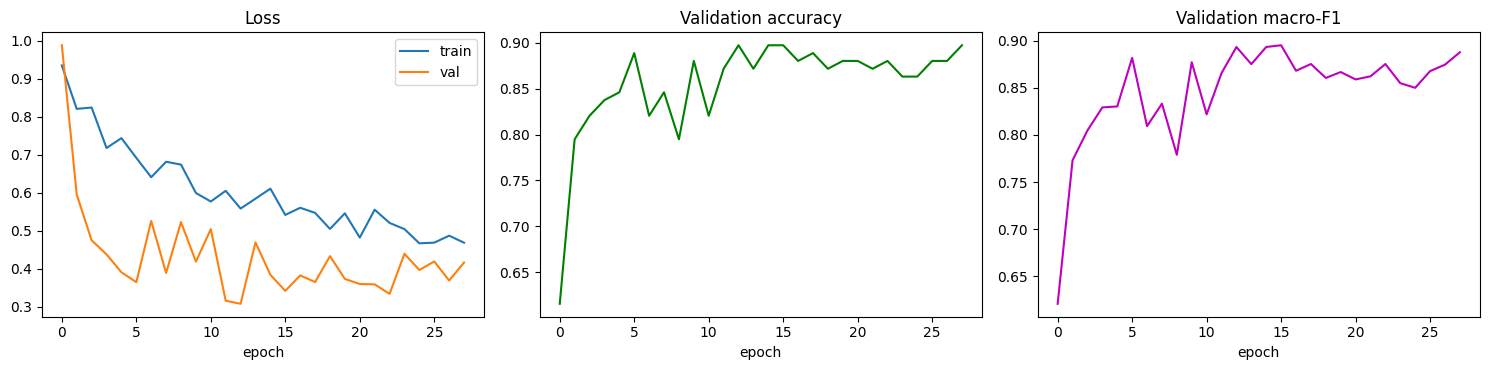

In [15]:
set_seed()
tr_loader, va_loader = make_cls_loaders(Ctr, ytr, Cva, yva)
te_loader = DataLoader(ClsDS(Cte, yte, False), batch_size=BATCH * 2, shuffle=False, num_workers=NUM_WORKERS)

models, cls_hists = [], []
for s in range(ENS_N):
    set_seed(SEED + s)
    m = DSORCNN(dropout=best_hp["dropout"])
    h, m = train_cls(m, tr_loader, va_loader, CLS_EPOCHS, best_hp["lr"], best_hp["weight_decay"], class_weights=cls_weights, verbose=(s == 0))
    models.append(m); cls_hists.append(h)
    torch.save(m.state_dict(), f"{OUT_DIR}/dsorcnn_best_seed{s}.pt")
    print(f"classifier {s+1}/{ENS_N}: best val macro-F1 {max(h['val_f1']):.4f}")
model, cls_hist = models[0], cls_hists[0]         # `model` (first seed) is used by the efficiency / explainability cells
torch.save(model.state_dict(), f"{OUT_DIR}/dsorcnn_best.pt")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(cls_hist["train_loss"], label="train"); ax[0].plot(cls_hist["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(cls_hist["val_acc"], color="g"); ax[1].set_title("Validation accuracy")
ax[2].plot(cls_hist["val_f1"], color="m"); ax[2].set_title("Validation macro-F1")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_dsorcnn_training.png", dpi=200); plt.show()


## 8. Test-set evaluation (touched only once, after model selection)

Primary test-set performance (image-level split):


,Metric,Value
0,Accuracy,0.8889
1,Accuracy 95% CI (bootstrap over test images),"[0.8291, 0.9402]"
2,Macro precision,0.8672
3,Macro recall,0.9115
4,Macro F1,0.8859
5,Macro AUC (OvR),0.9534


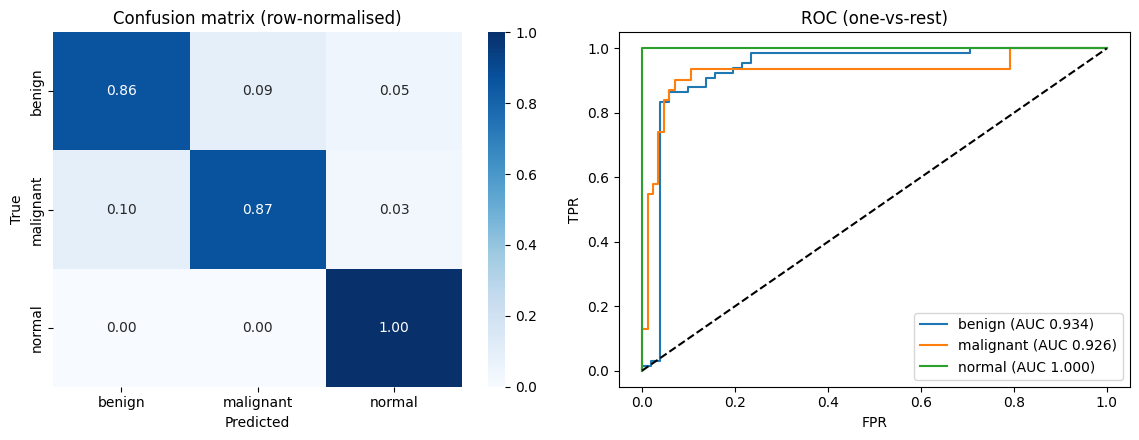

,coverage,n,accuracy
0,1.0,117,0.8889
1,0.9,105,0.9429
2,0.8,94,0.9468
3,0.7,82,0.9512


In [24]:
yt, yp, pr = evaluate_ens(models, te_loader, tta=True)           # ensemble of ENS_N seeds + flip-TTA
_, yp1, _ = evaluate_cls(model, te_loader)                        # single model, no TTA (for transparency)
#print(f"single model, no TTA: accuracy {accuracy_score(yt, yp1):.4f}  |  ensemble ({len(models)} models) + flip-TTA: {accuracy_score(yt, yp):.4f}")
acc = accuracy_score(yt, yp)
p, r, f, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
wf = f1_score(yt, yp, average="weighted")
auc_macro = roc_auc_score(label_binarize(yt, classes=list(range(NC))), pr, average="macro", multi_class="ovr")

rng = np.random.default_rng(SEED)
boots = [(yt[i] == yp[i]).mean() for i in (rng.integers(0, len(yt), len(yt)) for _ in range(2000))]
ci = np.percentile(boots, [2.5, 97.5])

summary = pd.DataFrame({"Metric": ["Accuracy", "Accuracy 95% CI (bootstrap over test images)", "Macro precision", "Macro recall", "Macro F1", "Macro AUC (OvR)"],
                        "Value": [f"{acc:.4f}", f"[{ci[0]:.4f}, {ci[1]:.4f}]", f"{p:.4f}", f"{r:.4f}", f"{f:.4f}", f"{auc_macro:.4f}"]})
print("Primary test-set performance (image-level split):"); display(summary)
summary.to_csv(f"{OUT_DIR}/table_test_summary.csv", index=False)

# per-class metrics
rep = pd.DataFrame(classification_report(yt, yp, target_names=CLASSES, output_dict=True, zero_division=0)).T.round(4)
rep.to_csv(f"{OUT_DIR}/table_test_per_class.csv")
results["classification"] = dict(accuracy=float(acc), acc_ci95=[float(ci[0]), float(ci[1])], macro_precision=float(p),
                                 macro_recall=float(r), macro_f1=float(f), weighted_f1=float(wf), macro_auc=float(auc_macro),
                                 n_test=int(len(yt)))
save_results()

cm = confusion_matrix(yt, yp)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.5))
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
ax[0].set_title("Confusion matrix (row-normalised)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")

yb = label_binarize(yt, classes=list(range(NC)))
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(yb[:, k], pr[:, k]); ax[1].plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.3f})")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC (one-vs-rest)"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_test_cm_roc.png", dpi=200); plt.show()
# selective prediction (risk-coverage): accuracy on the most confident fraction of the test images.
# NB: a confidence threshold for deployment must be chosen on VALIDATION data; this table is descriptive only.
conf = pr.max(1); order = np.argsort(-conf); hit = (yt == yp)[order]
rc = [dict(coverage=c, n=int(round(c * len(conf))), accuracy=float(hit[:int(round(c * len(conf)))].mean())) for c in (1.0, 0.9, 0.8, 0.7)]
display(pd.DataFrame(rc).round(4)); results["risk_coverage"] = rc; save_results()


## 9. Computational efficiency (parameters, FLOPs, latency)


In [17]:
from torch.utils.flop_counter import FlopCounterMode

def profile(m, name, size=IMG_SIZE):
    m = m.to(DEVICE).eval(); x = torch.randn(1, 3, size, size, device=DEVICE)
    params = sum(p.numel() for p in m.parameters()) / 1e6
    with torch.no_grad(), FlopCounterMode(display=False) as fc:
        m(x)
    gflops = fc.get_total_flops() / 1e9
    with torch.no_grad():
        for _ in range(5): m(x)
        if DEVICE == "cuda": torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(20): m(x)
        if DEVICE == "cuda": torch.cuda.synchronize()
    return dict(model=name, params_M=round(params, 2), GFLOPs=round(gflops, 2), latency_ms=round((time.time() - t0) / 20 * 1000, 2))

eff = pd.DataFrame([profile(oast, "OAST (segmentation)"), profile(model, "DSORCNN (classification)"),
                    profile(timm.create_model("densenet201", pretrained=False, num_classes=NC), "DenseNet-201 baseline")])
eff.loc[len(eff)] = dict(model="Pipeline OAST + DSORCNN", params_M=round(eff.params_M[:2].sum(), 2), GFLOPs=round(eff.GFLOPs[:2].sum(), 2),
                         latency_ms=round(eff.latency_ms[:2].sum(), 2))
display(eff); eff.to_csv(f"{OUT_DIR}/table_efficiency.csv", index=False)
results["efficiency"] = eff.to_dict("records")
save_results()
results["efficiency_note"] = (f"table lists ONE OAST and ONE DSORCNN; the reported test results use {n_members} OAST model(s) and {len(models)} DSORCNN model(s) with flip-TTA, "
                              f"so inference cost is roughly {n_members * 2}x / {len(models) * 2}x the single-model figures")
save_results()


,model,params_M,GFLOPs,latency_ms
0,OAST (segmentation),31.70,22.55,18.49
1,DSORCNN (classification),31.88,12.72,42.04
2,DenseNet-201 baseline,18.10,11.21,41.37
3,Pipeline OAST + DSORCNN,63.58,35.27,60.53


## 10. Explainability: Grad-CAM, LIME, SHAP

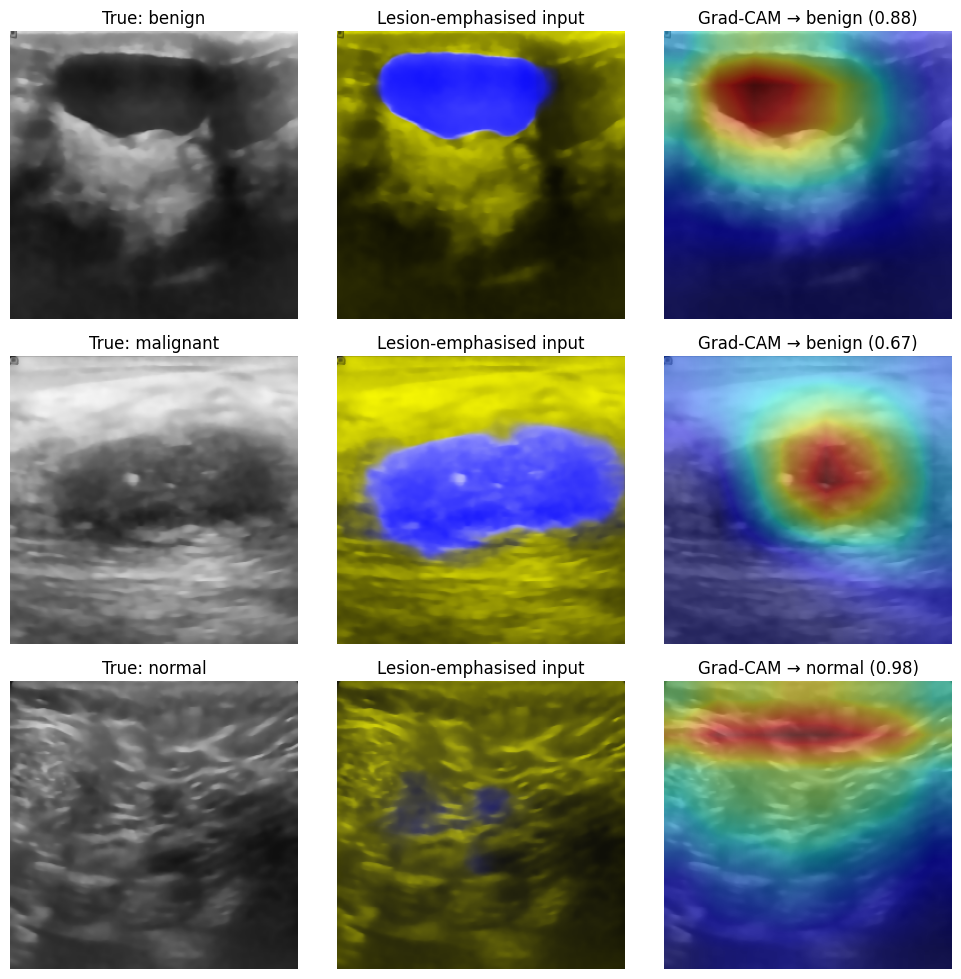

In [18]:
if RUN_XAI:
    class GradCAM:
        def __init__(self, model, layer):
            self.model, self.acts, self.grads = model, None, None
            layer.register_forward_hook(self._fwd)
        def _fwd(self, m, i, o):
            self.acts = o
            o.register_hook(lambda g: setattr(self, "grads", g))
        def __call__(self, x, cls=None):
            self.model.eval(); self.model.zero_grad()
            lg = self.model(x)
            cls = int(lg.argmax(1)) if cls is None else cls
            lg[0, cls].backward()
            w = self.grads.mean((2, 3), keepdim=True)
            cam = F.relu((w * self.acts).sum(1, keepdim=True))
            cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].detach().cpu().numpy()
            return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), cls, F.softmax(lg.detach(), 1)[0].cpu().numpy()

    gradcam = GradCAM(model, model.res)
    # one test example per class (first correctly classified one if possible)
    picks = []
    for k in range(NC):
        idx = np.where((yte == k) & (yp == k))[0]
        picks.append(int(idx[0]) if len(idx) else int(np.where(yte == k)[0][0]))

    fig, ax = plt.subplots(len(picks), 3, figsize=(10, 3.3 * len(picks)))
    for r, i in enumerate(picks):
        x = to_tensor(Cte[i])[None].to(DEVICE)
        cam, c_pred, prob = gradcam(x)
        ax[r, 0].imshow(Xte[i]); ax[r, 0].set_title(f"True: {CLASSES[yte[i]]}")
        ax[r, 1].imshow(Cte[i]); ax[r, 1].set_title("Lesion-emphasised input")
        ax[r, 2].imshow(Xte[i]); ax[r, 2].imshow(cam, cmap="jet", alpha=0.45)
        ax[r, 2].set_title(f"Grad-CAM → {CLASSES[c_pred]} ({prob[c_pred]:.2f})")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_gradcam.png", dpi=200); plt.show()
else:
    print('RUN_XAI=0 – explainability skipped for this run')


In [19]:
if RUN_XAI:
    model.res._forward_hooks.clear()   # removes the leftover Grad-CAM hook


  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

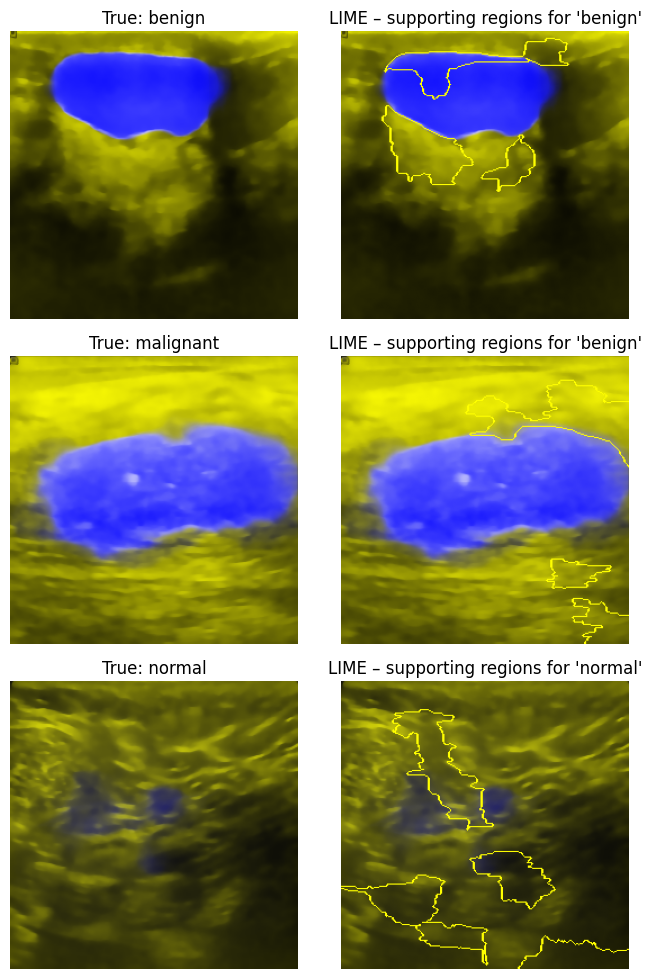

In [20]:
if RUN_XAI:
    # ---------------- LIME ----------------
    from lime import lime_image
    from skimage.segmentation import mark_boundaries

    @torch.no_grad()
    def predict_fn(batch):
        batch = np.asarray(batch).astype(np.float32)
        if batch.max() <= 1.0: batch = batch * 255
        batch = np.clip(batch, 0, 255).astype(np.uint8)
        model.eval(); out = []
        for i in range(0, len(batch), 32):
            xb = torch.stack([to_tensor(b) for b in batch[i:i + 32]]).to(DEVICE)
            out.append(F.softmax(model(xb).float(), 1).cpu().numpy())
        return np.concatenate(out)

    explainer = lime_image.LimeImageExplainer(random_state=SEED)
    fig, ax = plt.subplots(len(picks), 2, figsize=(7, 3.3 * len(picks)))
    for r, i in enumerate(picks):
        exp = explainer.explain_instance(Cte[i], predict_fn, top_labels=NC, hide_color=0, num_samples=1000, batch_size=32)
        lab = exp.top_labels[0]
        tmp, msk = exp.get_image_and_mask(lab, positive_only=True, num_features=5, hide_rest=False)
        ax[r, 0].imshow(Cte[i]); ax[r, 0].set_title(f"True: {CLASSES[yte[i]]}")
        ax[r, 1].imshow(mark_boundaries(tmp / 255.0, msk)); ax[r, 1].set_title(f"LIME – supporting regions for '{CLASSES[lab]}'")
        for a in ax[r]: a.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_lime.png", dpi=200); plt.show()


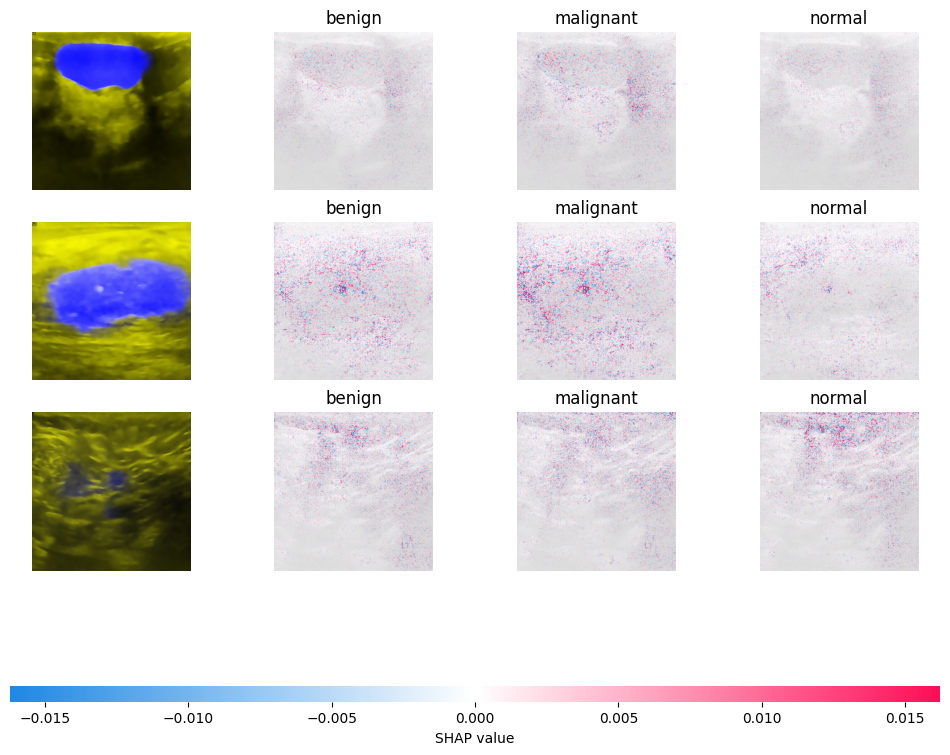

In [21]:
if RUN_XAI:
    # ---------------- SHAP (expected-gradients) ----------------
    import shap
    try:
        bg_idx = np.random.default_rng(SEED).choice(len(Ctr), 16, replace=False)
        bg = torch.stack([to_tensor(Ctr[i]) for i in bg_idx]).to(DEVICE)
        xt = torch.stack([to_tensor(Cte[i]) for i in picks]).to(DEVICE)
        model.eval()
        sv = shap.GradientExplainer(model, bg).shap_values(xt, nsamples=50)
        if isinstance(sv, list): sv_list = [np.transpose(s, (0, 2, 3, 1)) for s in sv]
        else:                    sv_list = [np.transpose(sv[..., k], (0, 2, 3, 1)) for k in range(sv.shape[-1])]
        px = np.clip(xt.cpu().numpy().transpose(0, 2, 3, 1) * STD + MEAN, 0, 1)
        shap.image_plot(sv_list, px, labels=np.tile(np.array(CLASSES), (len(picks), 1)), show=False)
        plt.savefig(f"{OUT_DIR}/fig_shap.png", dpi=200, bbox_inches="tight"); plt.show()
    except Exception as e:
        print("SHAP step failed (version mismatch between shap and torch is the usual cause):", repr(e))
        results["shap_error"] = repr(e); save_results()


## 11. Optional: 10-fold stratified cross-validation

Switch on with `RUN_CV=1` (environment variable) or in the configuration cell. With `CV_RETRAIN_OAST=True` the segmentation network is re-trained inside every fold, so the held-out fold is never seen by OAST. The OOA hyper-parameters were selected on the validation images, which are part of the CV pool; this slightly favours the CV estimate and should be stated in the Methods.

In [26]:
# (RUN_CV is set once, in the configuration cell – it is no longer overwritten here)
print('RUN_CV =', RUN_CV, '| CV_RETRAIN_OAST =', CV_RETRAIN_OAST)


RUN_CV = 1 | CV_RETRAIN_OAST = True


In [27]:
if RUN_CV:
    Xraw_pool, Mpool = np.concatenate([Xtr, Xva]), np.concatenate([Mtr, Mva])   # TVGCF images + masks (train + validation images only)
    ypool = np.concatenate([ytr, yva])
    skf = StratifiedKFold(10, shuffle=True, random_state=SEED); fold_acc = []
    for k, (a, b) in enumerate(skf.split(Xraw_pool, ypool), 1):
        set_seed(SEED + k)
        if CV_RETRAIN_OAST:
            # OAST is trained only on the training part of the fold (10% of it is held out for early stopping); the test fold is never used
            a_tr, a_es = train_test_split(a, test_size=0.10, stratify=ypool[a], random_state=SEED + k)
            s_tr = DataLoader(SegDS(Xraw_pool[a_tr], Mpool[a_tr], True), batch_size=BATCH, shuffle=True, drop_last=True, num_workers=NUM_WORKERS)
            s_es = DataLoader(SegDS(Xraw_pool[a_es], Mpool[a_es], False), batch_size=BATCH * 2, shuffle=False, num_workers=NUM_WORKERS)
            seg_k = OAST(pretrained=PRETRAINED, use_oga=USE_OGA)
            _, seg_k = train_seg(seg_k, s_tr, s_es, epochs=CV_SEG_EPOCHS, verbose=False)
            Pa, Pb = predict_seg(seg_k, Xraw_pool[a]), predict_seg(seg_k, Xraw_pool[b])
            del seg_k; torch.cuda.empty_cache()
            Xa, Xb = emphasise(Xraw_pool[a], Pa), emphasise(Xraw_pool[b], Pb)
        else:                                                                  # legacy behaviour: OAST trained on the main training split
            Xcls_pool = np.concatenate([Ctr, Cva]); Xa, Xb = Xcls_pool[a], Xcls_pool[b]
        trl, _ = make_cls_loaders(Xa, ypool[a])
        val = DataLoader(ClsDS(Xb, ypool[b], False), batch_size=BATCH * 2, shuffle=False, num_workers=NUM_WORKERS)
        m = DSORCNN(dropout=best_hp["dropout"])
        cw = torch.tensor(len(a) / (NC * np.bincount(ypool[a], minlength=NC)), dtype=torch.float32) ** CLS_WEIGHT_POWER; cw = cw / cw.mean()
        _, m = train_cls(m, trl, None, CV_EPOCHS, best_hp["lr"], best_hp["weight_decay"], class_weights=cw, verbose=False)
        t, pp, _ = evaluate_cls(m, val); fold_acc.append(accuracy_score(t, pp))
        print(f"Fold {k:02d}: accuracy {fold_acc[-1]:.4f}")
        del m; torch.cuda.empty_cache()
    cv = pd.DataFrame({"fold": range(1, 11), "accuracy": fold_acc}); display(cv.round(4))
    print(f"10-fold CV accuracy: mean {np.mean(fold_acc):.4f} ± {np.std(fold_acc):.4f} (range {min(fold_acc):.4f}–{max(fold_acc):.4f})")
    cv.to_csv(f"{OUT_DIR}/table_cv.csv", index=False)
    results["cv"] = dict(mean=float(np.mean(fold_acc)), std=float(np.std(fold_acc)), min=float(min(fold_acc)), max=float(max(fold_acc)),
                         oast_retrained_per_fold=CV_RETRAIN_OAST, folds=[float(x) for x in fold_acc])
    save_results()
    plt.figure(figsize=(7, 3.5)); plt.bar(cv.fold, cv.accuracy); plt.ylim(max(0, min(fold_acc) - 0.05), 1.0)
    plt.axhline(np.mean(fold_acc), color="r", ls="--", label="mean"); plt.legend(); plt.xlabel("fold"); plt.ylabel("accuracy"); plt.title("10-fold CV")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_cv.png", dpi=200); plt.show()
else:
    print("RUN_CV=0 – set RUN_CV=1 (environment variable or configuration cell) to run the 10-fold cross-validation.")


Fold 01: accuracy 0.8806


KeyboardInterrupt: 